In [ ]:
!pip install xgboost shap imbalanced-learn -q

In [ ]:
import io, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import (StratifiedKFold, train_test_split, cross_val_score)
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix,
                              classification_report, precision_recall_fscore_support)
from xgboost import XGBClassifier
import shap

print("All packages imported successfully.")

All packages imported successfully.


In [ ]:

# ════════════════════════════════════════════════════════════
# CELL 2 ▸ Load & Inspect Data
# Upload SpecialStudyData.csv via Files panel (left sidebar)
# ════════════════════════════════════════════════════════════

with open('SpecialStudyData.csv', 'r', encoding='utf-8') as f:
    lines = f.read().split('\n')
df_raw = pd.read_csv(io.StringIO('\n'.join(lines[4:])), low_memory=False)
df_raw = df_raw.drop(index=0).reset_index(drop=True)   # row 0 = units

print(f"Raw dataset shape : {df_raw.shape}")
print(f"Columns (first 20): {list(df_raw.columns[:20])}")


Raw dataset shape : (271, 83)
Columns (first 20): ['SAMPLE_ID', 'SAMPLE_FIELD_ID', 'SAMPLE_DATE', 'LAT_DEG', 'LONG_DEG', 'YEAR_CONSTRUCTION', 'WELL_TYPE', 'WELL_DEPTH', 'DIVISION', 'DISTRICT', 'THANA', 'UNION', 'MOUZA', 'GEOCODE', 'Al', 'AsIII', 'AsTot', 'B', 'Ba', 'Be']


In [ ]:

# ════════════════════════════════════════════════════════════
# CELL 3 ▸ Feature Selection & Cleaning
# ════════════════════════════════════════════════════════════

IOT_FEATURES = ['pH', 'SEC', 'T', 'WELL_DEPTH', 'Fe', 'Mn']
FEAT_LABELS  = ['pH', 'EC/SEC (uS/cm)', 'Temperature (C)',
                'Well Depth (m)', 'Iron Fe (mg/L)', 'Manganese Mn (mg/L)']
TARGET_COL   = 'AsTot'
BD_THRESHOLD = 50      # Bangladesh standard (ug/L)

# Sensor-only (no Fe/Mn kit) and Full Lab lists
SENSOR_ONLY  = ['pH', 'SEC', 'T', 'WELL_DEPTH']
# Full lab: all available numeric features except target & ids
SKIP_COLS    = ['SAMPLE_ID','SAMPLE_FIELD_ID','SAMPLE_DATE','LAT_DEG','LONG_DEG',
                'YEAR_CONSTRUCTION','WELL_TYPE','DIVISION','DISTRICT','THANA',
                'UNION','MOUZA','GEOCODE','label', TARGET_COL,
                'AsIII']  # AsIII is a sub-component of AsTot — exclude to avoid leakage

def clean_numeric(x):
    """Convert censored values '<0.04' to LOD/2; coerce others to float."""
    if pd.isna(x): return np.nan
    s = str(x).strip()
    if s.startswith('<'):
        try: return float(s.replace('<', '').strip()) / 2
        except: return np.nan
    try: return float(s)
    except: return np.nan

df = df_raw.copy()
for col in df.columns:
    if col not in ['SAMPLE_ID','SAMPLE_FIELD_ID','SAMPLE_DATE','DIVISION',
                   'DISTRICT','THANA','UNION','MOUZA','GEOCODE','WELL_TYPE']:
        df[col] = df[col].apply(clean_numeric)

df = df.dropna(subset=[TARGET_COL]).reset_index(drop=True)
df['label'] = (df[TARGET_COL] >= BD_THRESHOLD).astype(int)

# Full lab feature list (numeric, no leakage)
FULL_COLS = [c for c in df.columns
             if c not in SKIP_COLS and df[c].dtype in [np.float64, np.int64, float, int]
             and df[c].notna().mean() > 0.5]

print(f"\nSamples after cleaning : {len(df)}")
print(f"Safe   (< {BD_THRESHOLD} ug/L)  : {sum(df['label']==0)} wells ({sum(df['label']==0)/len(df)*100:.1f}%)")
print(f"Unsafe (>= {BD_THRESHOLD} ug/L) : {sum(df['label']==1)} wells ({sum(df['label']==1)/len(df)*100:.1f}%)")
print(f"Arsenic range          : {df[TARGET_COL].min():.1f} - {df[TARGET_COL].max():.1f} ug/L")
print(f"\nMissing values in IoT features (%):")
print(df[IOT_FEATURES].isnull().mean().mul(100).round(1).to_string())
print(f"\nFull lab feature count : {len(FULL_COLS)}")




Samples after cleaning : 271
Safe   (< 50 ug/L)  : 163 wells (60.1%)
Unsafe (>= 50 ug/L) : 108 wells (39.9%)
Arsenic range          : 0.2 - 2400.0 ug/L

Missing values in IoT features (%):
pH            4.1
SEC           0.0
T             0.0
WELL_DEPTH    3.7
Fe            0.0
Mn            0.0

Full lab feature count : 63


In [ ]:

# ════════════════════════════════════════════════════════════
# CELL 4 ▸ SMOTE Synthetic Oversampling
# Generates synthetic minority-class samples via KNN interpolation
# Better than random oversampling — avoids exact duplicates
# ════════════════════════════════════════════════════════════

def smote_resample(X, y, random_state=42, k_neighbors=5):
    """
    Simple SMOTE implementation.
    For each minority sample, pick a random KNN neighbor
    and interpolate a synthetic point between them.
    """
    rng     = np.random.RandomState(random_state)
    X_arr   = X.values if hasattr(X, 'values') else np.array(X)
    y_arr   = np.array(y)
    cols    = X.columns.tolist() if hasattr(X, 'columns') else None
    classes, counts = np.unique(y_arr, return_counts=True)
    max_c   = counts.max()
    X_out   = list(X_arr)
    y_out   = list(y_arr)

    for cls, cnt in zip(classes, counts):
        if cnt == max_c:
            continue
        X_min   = X_arr[y_arr == cls]
        n_synth = max_c - cnt
        k       = min(k_neighbors, len(X_min) - 1)
        nn      = NearestNeighbors(n_neighbors=k + 1).fit(X_min)
        _, idxs = nn.kneighbors(X_min)
        for _ in range(n_synth):
            i   = rng.randint(0, len(X_min))
            j   = idxs[i][rng.randint(1, k + 1)]
            lam = rng.random()
            synth = X_min[i] + lam * (X_min[j] - X_min[i])
            X_out.append(synth)
            y_out.append(cls)

    X_out = np.array(X_out); y_out = np.array(y_out)
    perm  = rng.permutation(len(y_out))
    X_df  = pd.DataFrame(X_out[perm], columns=cols) if cols else X_out[perm]
    return X_df, pd.Series(y_out[perm], name='label')

# Apply SMOTE to IoT features
imputer = SimpleImputer(strategy='median')
X_imp   = pd.DataFrame(imputer.fit_transform(df[IOT_FEATURES]), columns=IOT_FEATURES)
y_raw   = df['label'].copy()

X_sm, y_sm = smote_resample(X_imp, y_raw)
X_train, X_test, y_train, y_test = train_test_split(
    X_sm, y_sm, test_size=0.2, random_state=42, stratify=y_sm
)
print(f"After SMOTE          : {dict(y_sm.value_counts())}")
print(f"Train: {len(X_train)} | Test: {len(X_test)}")



After SMOTE          : {0: np.int64(163), 1: np.int64(163)}
Train: 260 | Test: 66


In [ ]:
# ============================================================
# GROUNDWATER ARSENIC SAFETY PREDICTION — v2 (Full Version)
# Low-Cost IoT Sensor-Based ML Framework — Bangladesh
# Google Colab Ready | BGS/DFID/DPHE Dataset
# Threshold: Bangladesh Standard = 50 ug/L
# ============================================================
# Improvements over v1:
#   1. SMOTE (synthetic oversampling) replaces random oversampling
#   2. CV mean ± std reported for every model
#   3. Scenario comparison: Full Lab vs IoT Kit vs Sensor Only
#   4. Threshold sensitivity: WHO 10 vs BD 50 vs Lenient 100
#   5. Per-class recall bar chart added
# ============================================================


# ════════════════════════════════════════════════════════════
# CELL 1 ▸ Install & Import
# ════════════════════════════════════════════════════════════

# Uncomment next line in Colab:
# !pip install xgboost shap imbalanced-learn -q

import io, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import (StratifiedKFold, train_test_split, cross_val_score)
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix,
                              classification_report, precision_recall_fscore_support)
from xgboost import XGBClassifier
import shap

print("All packages imported successfully.")


# ════════════════════════════════════════════════════════════
# CELL 2 ▸ Load & Inspect Data
# Upload SpecialStudyData.csv via Files panel (left sidebar)
# ════════════════════════════════════════════════════════════

with open('SpecialStudyData.csv', 'r', encoding='utf-8') as f:
    lines = f.read().split('\n')
df_raw = pd.read_csv(io.StringIO('\n'.join(lines[4:])), low_memory=False)
df_raw = df_raw.drop(index=0).reset_index(drop=True)   # row 0 = units

print(f"Raw dataset shape : {df_raw.shape}")
print(f"Columns (first 20): {list(df_raw.columns[:20])}")


# ════════════════════════════════════════════════════════════
# CELL 3 ▸ Feature Selection & Cleaning
# ════════════════════════════════════════════════════════════

IOT_FEATURES = ['pH', 'SEC', 'T', 'WELL_DEPTH', 'Fe', 'Mn']
FEAT_LABELS  = ['pH', 'EC/SEC (uS/cm)', 'Temperature (C)',
                'Well Depth (m)', 'Iron Fe (mg/L)', 'Manganese Mn (mg/L)']
TARGET_COL   = 'AsTot'
BD_THRESHOLD = 50      # Bangladesh standard (ug/L)

# Sensor-only (no Fe/Mn kit) and Full Lab lists
SENSOR_ONLY  = ['pH', 'SEC', 'T', 'WELL_DEPTH']
# Full lab: all available numeric features except target & ids
SKIP_COLS    = ['SAMPLE_ID','SAMPLE_FIELD_ID','SAMPLE_DATE','LAT_DEG','LONG_DEG',
                'YEAR_CONSTRUCTION','WELL_TYPE','DIVISION','DISTRICT','THANA',
                'UNION','MOUZA','GEOCODE','label', TARGET_COL,
                'AsIII']  # AsIII is a sub-component of AsTot — exclude to avoid leakage

def clean_numeric(x):
    """Convert censored values '<0.04' to LOD/2; coerce others to float."""
    if pd.isna(x): return np.nan
    s = str(x).strip()
    if s.startswith('<'):
        try: return float(s.replace('<', '').strip()) / 2
        except: return np.nan
    try: return float(s)
    except: return np.nan

df = df_raw.copy()
for col in df.columns:
    if col not in ['SAMPLE_ID','SAMPLE_FIELD_ID','SAMPLE_DATE','DIVISION',
                   'DISTRICT','THANA','UNION','MOUZA','GEOCODE','WELL_TYPE']:
        df[col] = df[col].apply(clean_numeric)

df = df.dropna(subset=[TARGET_COL]).reset_index(drop=True)
df['label'] = (df[TARGET_COL] >= BD_THRESHOLD).astype(int)

# Full lab feature list (numeric, no leakage)
FULL_COLS = [c for c in df.columns
             if c not in SKIP_COLS and df[c].dtype in [np.float64, np.int64, float, int]
             and df[c].notna().mean() > 0.5]

print(f"\nSamples after cleaning : {len(df)}")
print(f"Safe   (< {BD_THRESHOLD} ug/L)  : {sum(df['label']==0)} wells ({sum(df['label']==0)/len(df)*100:.1f}%)")
print(f"Unsafe (>= {BD_THRESHOLD} ug/L) : {sum(df['label']==1)} wells ({sum(df['label']==1)/len(df)*100:.1f}%)")
print(f"Arsenic range          : {df[TARGET_COL].min():.1f} - {df[TARGET_COL].max():.1f} ug/L")
print(f"\nMissing values in IoT features (%):")
print(df[IOT_FEATURES].isnull().mean().mul(100).round(1).to_string())
print(f"\nFull lab feature count : {len(FULL_COLS)}")


# ════════════════════════════════════════════════════════════
# CELL 4 ▸ SMOTE Synthetic Oversampling
# Generates synthetic minority-class samples via KNN interpolation
# Better than random oversampling — avoids exact duplicates
# ════════════════════════════════════════════════════════════

def smote_resample(X, y, random_state=42, k_neighbors=5):
    """
    Simple SMOTE implementation.
    For each minority sample, pick a random KNN neighbor
    and interpolate a synthetic point between them.
    """
    rng     = np.random.RandomState(random_state)
    X_arr   = X.values if hasattr(X, 'values') else np.array(X)
    y_arr   = np.array(y)
    cols    = X.columns.tolist() if hasattr(X, 'columns') else None
    classes, counts = np.unique(y_arr, return_counts=True)
    max_c   = counts.max()
    X_out   = list(X_arr)
    y_out   = list(y_arr)

    for cls, cnt in zip(classes, counts):
        if cnt == max_c:
            continue
        X_min   = X_arr[y_arr == cls]
        n_synth = max_c - cnt
        k       = min(k_neighbors, len(X_min) - 1)
        nn      = NearestNeighbors(n_neighbors=k + 1).fit(X_min)
        _, idxs = nn.kneighbors(X_min)
        for _ in range(n_synth):
            i   = rng.randint(0, len(X_min))
            j   = idxs[i][rng.randint(1, k + 1)]
            lam = rng.random()
            synth = X_min[i] + lam * (X_min[j] - X_min[i])
            X_out.append(synth)
            y_out.append(cls)

    X_out = np.array(X_out); y_out = np.array(y_out)
    perm  = rng.permutation(len(y_out))
    X_df  = pd.DataFrame(X_out[perm], columns=cols) if cols else X_out[perm]
    return X_df, pd.Series(y_out[perm], name='label')

# Apply SMOTE to IoT features
imputer = SimpleImputer(strategy='median')
X_imp   = pd.DataFrame(imputer.fit_transform(df[IOT_FEATURES]), columns=IOT_FEATURES)
y_raw   = df['label'].copy()

X_sm, y_sm = smote_resample(X_imp, y_raw)
X_train, X_test, y_train, y_test = train_test_split(
    X_sm, y_sm, test_size=0.2, random_state=42, stratify=y_sm
)
print(f"After SMOTE          : {dict(y_sm.value_counts())}")
print(f"Train: {len(X_train)} | Test: {len(X_test)}")


# ════════════════════════════════════════════════════════════
# CELL 5 ▸ Train & Compare Models (CV mean +/- std)
# ════════════════════════════════════════════════════════════

models = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest (RF)'  : RandomForestClassifier(n_estimators=300, random_state=42),
    'MLP (ANN)'           : MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42),
    'XGBoost'             : XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                                          eval_metric='logloss', random_state=42, verbosity=0),
    'Gradient Boosting'   : GradientBoostingClassifier(n_estimators=300, max_depth=4,
                                                        learning_rate=0.05, random_state=42),
}

cv5     = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

print(f"\n{'Model':<25} {'CV Acc':>8} {'(+/-std)':>9} | {'TestAcc':>8} {'F1':>7} {'AUC':>7}")
print("-" * 68)

for name, model in models.items():
    cv_acc = cross_val_score(model, X_train, y_train, cv=cv5, scoring='accuracy')
    model.fit(X_train, y_train)
    yp  = model.predict(X_test)
    ypr = model.predict_proba(X_test)[:, 1]
    results[name] = {
        'cv_mean'  : cv_acc.mean(),
        'cv_std'   : cv_acc.std(),
        'test_acc' : accuracy_score(y_test, yp),
        'test_ba'  : balanced_accuracy_score(y_test, yp),
        'test_f1'  : f1_score(y_test, yp),
        'test_auc' : roc_auc_score(y_test, ypr),
        'y_pred'   : yp,
        'y_prob'   : ypr,
        'cm'       : confusion_matrix(y_test, yp),
        'model'    : model,
    }
    r = results[name]
    print(f"{name:<25} {r['cv_mean']:>8.4f} {r['cv_std']:>9.4f} | "
          f"{r['test_acc']:>8.4f} {r['test_f1']:>7.4f} {r['test_auc']:>7.4f}")

best_name = max(results, key=lambda n: results[n]['test_auc'])
print(f"\nBest Model (by AUC): {best_name}")
print(classification_report(y_test, results[best_name]['y_pred'],
                             target_names=['Safe', 'Unsafe']))



All packages imported successfully.
Raw dataset shape : (271, 83)
Columns (first 20): ['SAMPLE_ID', 'SAMPLE_FIELD_ID', 'SAMPLE_DATE', 'LAT_DEG', 'LONG_DEG', 'YEAR_CONSTRUCTION', 'WELL_TYPE', 'WELL_DEPTH', 'DIVISION', 'DISTRICT', 'THANA', 'UNION', 'MOUZA', 'GEOCODE', 'Al', 'AsIII', 'AsTot', 'B', 'Ba', 'Be']

Samples after cleaning : 271
Safe   (< 50 ug/L)  : 163 wells (60.1%)
Unsafe (>= 50 ug/L) : 108 wells (39.9%)
Arsenic range          : 0.2 - 2400.0 ug/L

Missing values in IoT features (%):
pH            4.1
SEC           0.0
T             0.0
WELL_DEPTH    3.7
Fe            0.0
Mn            0.0

Full lab feature count : 63
After SMOTE          : {0: np.int64(163), 1: np.int64(163)}
Train: 260 | Test: 66

Model                       CV Acc  (+/-std) |  TestAcc      F1     AUC
--------------------------------------------------------------------
Logistic Regression         0.7692    0.0644 |   0.7879  0.8000  0.8742
Random Forest (RF)          0.8346    0.0196 |   0.8182  0.8378  0.92

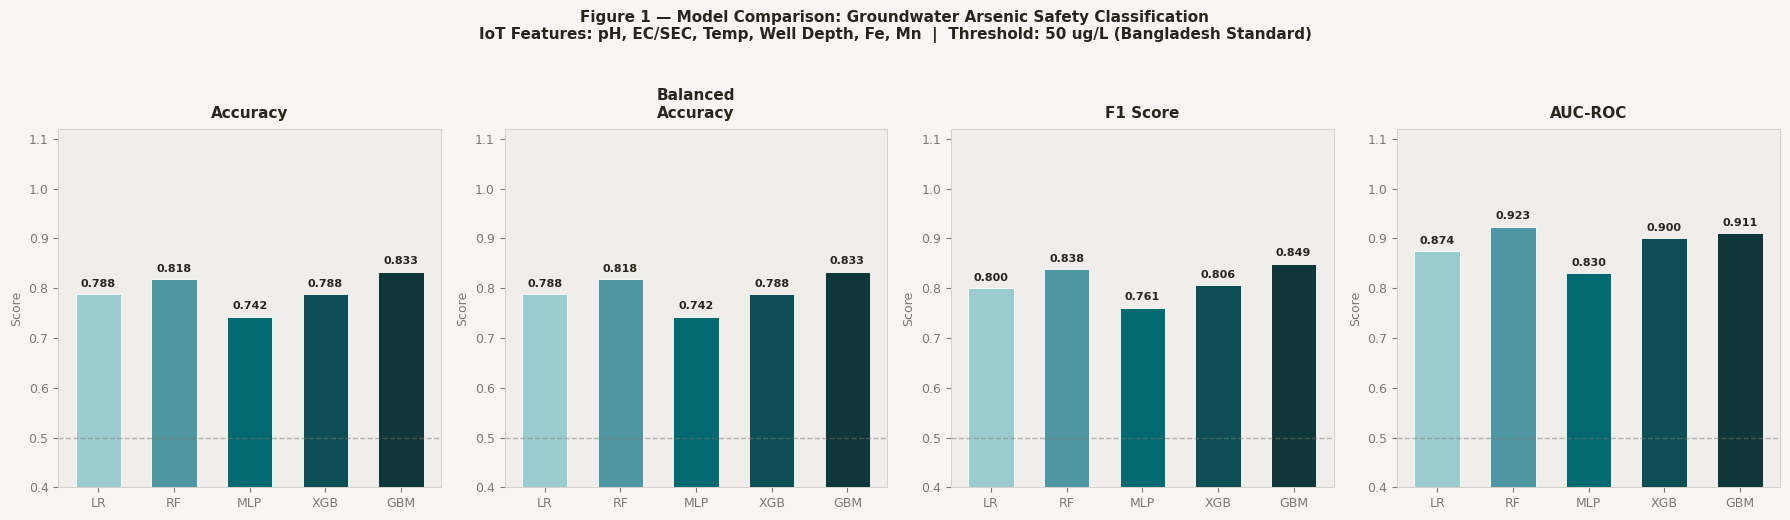

Saved: figure1_model_comparison.png


In [ ]:

# ════════════════════════════════════════════════════════════
# CELL 6 ▸ Figure 1 — Model Comparison (CV + Test)
# ════════════════════════════════════════════════════════════

C_BG='#f7f6f2'; C_SURF='#f0eeea'; C_TEXT='#28251d'
C_MUTED='#7a7974'; C_TEAL='#01696f'; C_BORDER='#d4d1ca'
BAR_COLS=['#9acbcf','#4f98a3','#01696f','#0c4e54','#0f3638']

model_keys  = list(results.keys())
short_names = ['LR', 'RF', 'MLP', 'XGB', 'GBM']
metric_keys = ['test_acc', 'test_ba', 'test_f1', 'test_auc']
metric_lbls = ['Accuracy', 'Balanced\nAccuracy', 'F1 Score', 'AUC-ROC']

fig, axes = plt.subplots(1, 4, figsize=(18, 5), facecolor=C_BG)
fig.suptitle('Figure 1 — Model Comparison: Groundwater Arsenic Safety Classification\n'
             'IoT Features: pH, EC/SEC, Temp, Well Depth, Fe, Mn  |  Threshold: 50 ug/L (Bangladesh Standard)',
             fontsize=11, fontweight='bold', color=C_TEXT, y=1.03)

for ax, key, lbl in zip(axes, metric_keys, metric_lbls):
    vals = [results[n][key] for n in model_keys]
    bars = ax.bar(short_names, vals, color=BAR_COLS, edgecolor='white', lw=0.6, width=0.6)
    ax.set_facecolor(C_SURF)
    for sp in ax.spines.values(): sp.set_edgecolor(C_BORDER); sp.set_linewidth(0.7)
    ax.set_ylim(0.4, 1.12)
    ax.axhline(0.5, color=C_MUTED, ls='--', lw=1, alpha=0.5)
    ax.set_title(lbl, fontsize=11, fontweight='bold', color=C_TEXT, pad=8)
    ax.tick_params(colors=C_MUTED, labelsize=9)
    ax.set_ylabel('Score', fontsize=9, color=C_MUTED)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.015,
                f'{val:.3f}', ha='center', fontsize=8, color=C_TEXT, fontweight='600')

plt.tight_layout()
plt.savefig('figure1_model_comparison.png', dpi=150, bbox_inches='tight', facecolor=C_BG)
plt.show()
print("Saved: figure1_model_comparison.png")


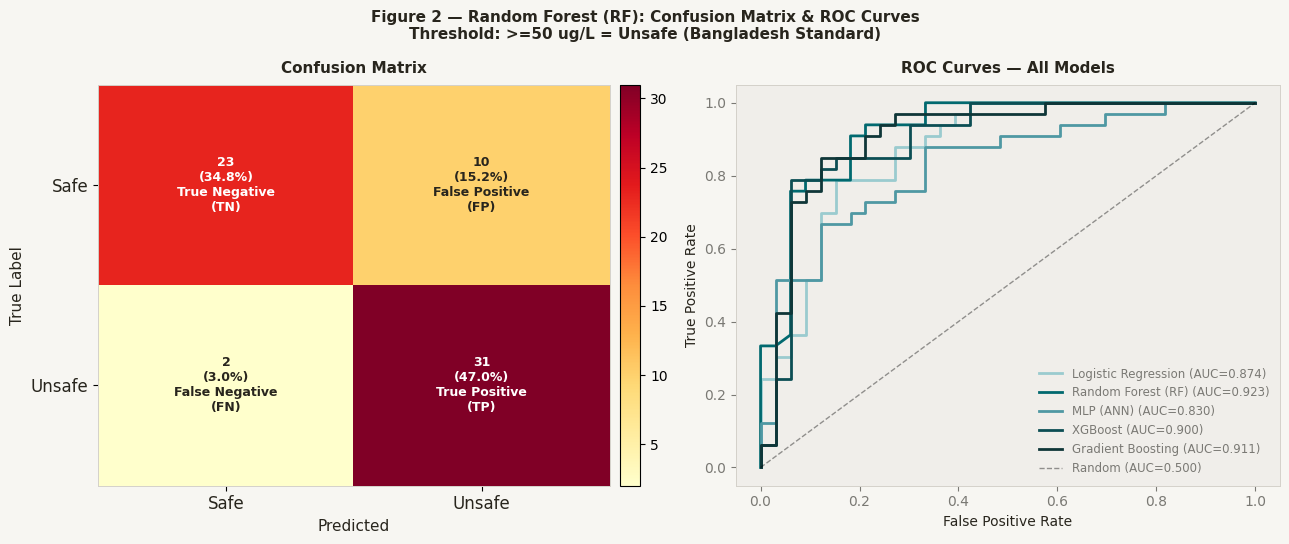

Saved: figure2_cm_roc.png


In [ ]:

# ════════════════════════════════════════════════════════════
# CELL 7 ▸ Figure 2 — Confusion Matrix + ROC Curves
# ════════════════════════════════════════════════════════════

best = results[best_name]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), facecolor=C_BG)
fig.suptitle(f'Figure 2 — {best_name}: Confusion Matrix & ROC Curves\n'
             f'Threshold: >=50 ug/L = Unsafe (Bangladesh Standard)',
             fontsize=11, fontweight='bold', color=C_TEXT)

# Confusion matrix
cm = best['cm']
im = ax1.imshow(cm, cmap='YlOrRd', aspect='auto')
ax1.set_xticks([0,1]); ax1.set_yticks([0,1])
ax1.set_xticklabels(['Safe', 'Unsafe'], fontsize=12, color=C_TEXT)
ax1.set_yticklabels(['Safe', 'Unsafe'], fontsize=12, color=C_TEXT)
ax1.set_xlabel('Predicted', fontsize=11, color=C_TEXT)
ax1.set_ylabel('True Label', fontsize=11, color=C_TEXT)
ax1.set_title('Confusion Matrix', fontsize=11, fontweight='bold', color=C_TEXT, pad=8)
ax1.set_facecolor(C_SURF)
for sp in ax1.spines.values(): sp.set_edgecolor(C_BORDER); sp.set_linewidth(0.7)
total = cm.sum()
labels_cm = [['True Negative\n(TN)', 'False Positive\n(FP)'],
             ['False Negative\n(FN)', 'True Positive\n(TP)']]
for i in range(2):
    for j in range(2):
        pct = cm[i,j] / total * 100
        ax1.text(j, i, f'{cm[i,j]}\n({pct:.1f}%)\n{labels_cm[i][j]}',
                 ha='center', va='center', fontsize=9, fontweight='bold',
                 color='white' if cm[i,j] > cm.max() * 0.55 else C_TEXT)
plt.colorbar(im, ax=ax1, fraction=0.04, pad=0.02)

# ROC curves
ax2.set_facecolor(C_SURF)
for sp in ax2.spines.values(): sp.set_edgecolor(C_BORDER); sp.set_linewidth(0.7)
roc_colors = ['#9acbcf', '#01696f', '#4f98a3', '#0c4e54', '#0f3638']
for (name, r), col in zip(results.items(), roc_colors):
    fpr, tpr, _ = roc_curve(y_test, r['y_prob'])
    ax2.plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUC={r['test_auc']:.3f})")
ax2.plot([0,1],[0,1], 'k--', lw=1, alpha=0.4, label='Random (AUC=0.500)')
ax2.set_xlabel('False Positive Rate', fontsize=10, color=C_TEXT)
ax2.set_ylabel('True Positive Rate', fontsize=10, color=C_TEXT)
ax2.set_title('ROC Curves — All Models', fontsize=11, fontweight='bold', color=C_TEXT, pad=8)
ax2.legend(fontsize=8.5, frameon=False, labelcolor=C_MUTED)
ax2.tick_params(colors=C_MUTED)

plt.tight_layout()
plt.savefig('figure2_cm_roc.png', dpi=150, bbox_inches='tight', facecolor=C_BG)
plt.show()
print("Saved: figure2_cm_roc.png")



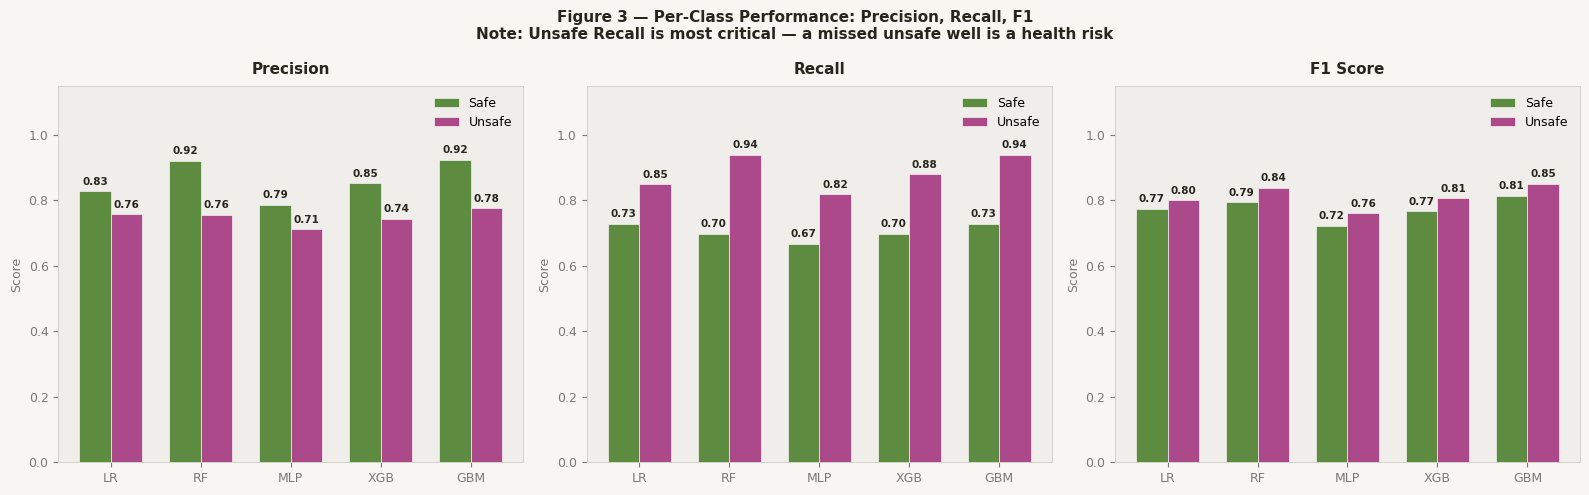

Saved: figure3_per_class.png


In [ ]:

# ════════════════════════════════════════════════════════════
# CELL 8 ▸ Figure 3 — Per-Class Precision, Recall, F1
# (Unsafe class recall is most critical for safety applications)
# ════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(16, 5), facecolor=C_BG)
fig.suptitle('Figure 3 — Per-Class Performance: Precision, Recall, F1\n'
             'Note: Unsafe Recall is most critical — a missed unsafe well is a health risk',
             fontsize=11, fontweight='bold', color=C_TEXT)

metric_fns = [
    ('Precision', lambda yp: precision_recall_fscore_support(y_test, yp, average=None, labels=[0,1])[0]),
    ('Recall',    lambda yp: precision_recall_fscore_support(y_test, yp, average=None, labels=[0,1])[1]),
    ('F1 Score',  lambda yp: precision_recall_fscore_support(y_test, yp, average=None, labels=[0,1])[2]),
]
x = np.arange(len(models))
w = 0.35

for ax, (metric_name, metric_fn) in zip(axes, metric_fns):
    safe_vals   = [metric_fn(results[n]['y_pred'])[0] for n in model_keys]
    unsafe_vals = [metric_fn(results[n]['y_pred'])[1] for n in model_keys]
    b1 = ax.bar(x - w/2, safe_vals,   w, color='#437a22', edgecolor='white', lw=0.5, label='Safe',   alpha=0.85)
    b2 = ax.bar(x + w/2, unsafe_vals, w, color='#a12c7b', edgecolor='white', lw=0.5, label='Unsafe', alpha=0.85)
    ax.set_facecolor(C_SURF)
    for sp in ax.spines.values(): sp.set_edgecolor(C_BORDER); sp.set_linewidth(0.7)
    ax.set_ylim(0, 1.15)
    ax.set_xticks(x); ax.set_xticklabels(short_names, fontsize=9)
    ax.set_title(metric_name, fontsize=11, fontweight='bold', color=C_TEXT, pad=8)
    ax.tick_params(colors=C_MUTED, labelsize=9)
    ax.set_ylabel('Score', fontsize=9, color=C_MUTED)
    ax.legend(fontsize=9, frameon=False)
    for bar, val in zip(list(b1) + list(b2), safe_vals + unsafe_vals):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.02,
                f'{val:.2f}', ha='center', fontsize=7.5, color=C_TEXT, fontweight='600')

plt.tight_layout()
plt.savefig('figure3_per_class.png', dpi=150, bbox_inches='tight', facecolor=C_BG)
plt.show()
print("Saved: figure3_per_class.png")



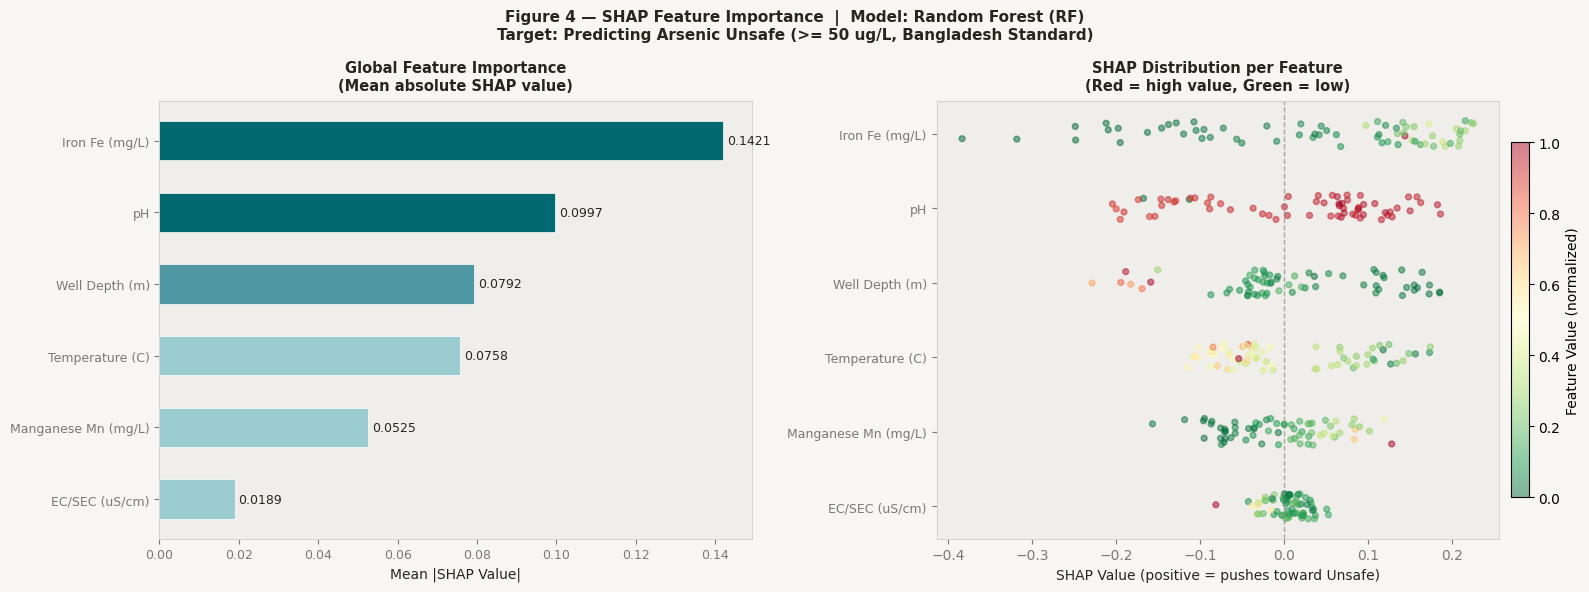

Saved: figure4_shap.png


In [ ]:
# ── CELL 9 ▸ Figure 4 — SHAP Feature Importance ──────────────

best_model_obj = results[best_name]['model']
shap_explainer = shap.TreeExplainer(best_model_obj)
shap_values    = shap_explainer.shap_values(X_test)

# Fix: shape (66, 6, 2) → take [:, :, 1] for Unsafe class
if isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_unsafe = shap_values[:, :, 1]
elif isinstance(shap_values, list):
    shap_unsafe = np.array(shap_values[1])
else:
    shap_unsafe = shap_values

mean_shap   = np.abs(shap_unsafe).mean(axis=0)   # now shape (6,)
sorted_idx  = np.argsort(mean_shap)
shap_sorted = mean_shap[sorted_idx]
feat_sorted = [FEAT_LABELS[int(i)] for i in sorted_idx]

fi_cols = [C_TEAL if v >= sorted(shap_sorted)[-2] else
           '#4f98a3' if v >= np.median(shap_sorted) else '#9acbcf'
           for v in shap_sorted]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), facecolor=C_BG)
fig.suptitle(f'Figure 4 — SHAP Feature Importance  |  Model: {best_name}\n'
             f'Target: Predicting Arsenic Unsafe (>= 50 ug/L, Bangladesh Standard)',
             fontsize=11, fontweight='bold', color=C_TEXT)

# Bar: mean |SHAP|
ax1.barh(feat_sorted, shap_sorted, color=fi_cols, edgecolor='white', lw=0.5, height=0.55)
ax1.set_facecolor(C_SURF)
for sp in ax1.spines.values(): sp.set_edgecolor(C_BORDER); sp.set_linewidth(0.7)
ax1.set_xlabel('Mean |SHAP Value|', fontsize=10, color=C_TEXT)
ax1.set_title('Global Feature Importance\n(Mean absolute SHAP value)', fontsize=10.5,
              fontweight='bold', color=C_TEXT, pad=8)
ax1.tick_params(colors=C_MUTED, labelsize=9)
for i, val in enumerate(shap_sorted):
    ax1.text(val + 0.001, i, f'{val:.4f}', va='center', fontsize=9, color=C_TEXT)

# Beeswarm-style scatter
X_test_arr = X_test.values if hasattr(X_test, 'values') else np.array(X_test)
ax2.set_facecolor(C_SURF)
for sp in ax2.spines.values(): sp.set_edgecolor(C_BORDER); sp.set_linewidth(0.7)
for i, (fi, fl) in enumerate(zip(sorted_idx, feat_sorted)):
    sv      = shap_unsafe[:, int(fi)]
    fv      = X_test_arr[:, int(fi)]
    fv_norm = (fv - fv.min()) / (fv.max() - fv.min() + 1e-9)
    sc = ax2.scatter(sv,
                     np.full(len(sv), i) + np.random.uniform(-0.18, 0.18, len(sv)),
                     c=fv_norm, cmap='RdYlGn_r', alpha=0.5, s=18, vmin=0, vmax=1)

ax2.axvline(0, color=C_MUTED, lw=1, ls='--', alpha=0.6)
ax2.set_yticks(range(len(feat_sorted)))
ax2.set_yticklabels(feat_sorted, fontsize=9, color=C_TEXT)
ax2.set_xlabel('SHAP Value (positive = pushes toward Unsafe)', fontsize=10, color=C_TEXT)
ax2.set_title('SHAP Distribution per Feature\n(Red = high value, Green = low)', fontsize=10.5,
              fontweight='bold', color=C_TEXT, pad=8)
ax2.tick_params(colors=C_MUTED)
plt.colorbar(sc, ax=ax2, label='Feature Value (normalized)', fraction=0.03, pad=0.02)

plt.tight_layout()
plt.savefig('figure4_shap.png', dpi=150, bbox_inches='tight', facecolor=C_BG)
plt.show()
print("Saved: figure4_shap.png")

Scenario Comparison (RF, SMOTE, 5-fold CV):
Scenario               n_feat      Acc       F1      AUC
-------------------------------------------------------
Full Lab                   63   0.9242   0.9296   0.9835
IoT + Fe/Mn Kit             6   0.8182   0.8378   0.9233
Sensor Only                 4   0.7879   0.8108   0.8471


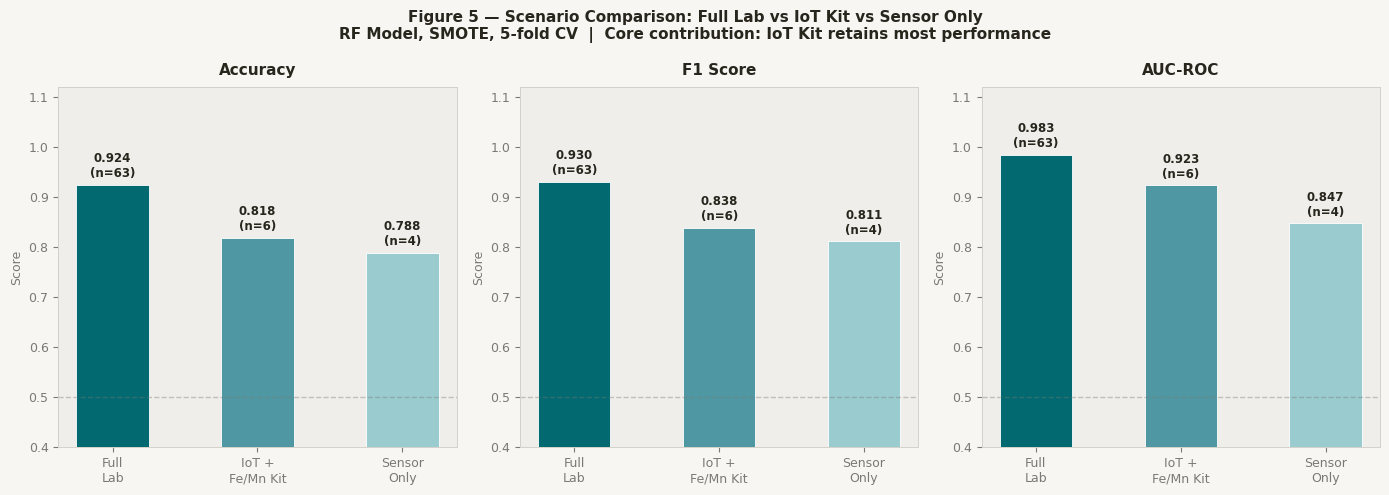

Saved: figure5_scenario_comparison.png


In [ ]:

# ════════════════════════════════════════════════════════════
# CELL 10 ▸ Figure 5 — Scenario Comparison
# Full Lab vs IoT + Fe/Mn Kit vs Sensor Only
# This is the core contribution of the paper
# ════════════════════════════════════════════════════════════

FULL_COLS   = [c for c in df_raw.drop(index=0).columns
               if c not in ['SAMPLE_ID','SAMPLE_FIELD_ID','SAMPLE_DATE','LAT_DEG','LONG_DEG',
                             'YEAR_CONSTRUCTION','WELL_TYPE','DIVISION','DISTRICT','THANA',
                             'UNION','MOUZA','GEOCODE','label','AsTot','AsIII']
               and c in df.columns and df[c].dtype in [np.float64, np.int64]
               and df[c].notna().mean() > 0.5]

scenarios    = {
    'Full Lab'           : FULL_COLS,
    'IoT + Fe/Mn Kit'   : IOT_FEATURES,
    'Sensor Only'        : SENSOR_ONLY,
}
scen_results = {}

print("Scenario Comparison (RF, SMOTE, 5-fold CV):")
print(f"{'Scenario':<22} {'n_feat':>6} {'Acc':>8} {'F1':>8} {'AUC':>8}")
print("-"*55)

for s_name, feats in scenarios.items():
    Xs   = pd.DataFrame(
        SimpleImputer(strategy='median').fit_transform(df[feats]), columns=feats
    )
    Xs2, ys2 = smote_resample(Xs, y_raw)
    Xtr, Xte, ytr, yte = train_test_split(Xs2, ys2, test_size=0.2, random_state=42, stratify=ys2)
    m = RandomForestClassifier(n_estimators=300, random_state=42)
    m.fit(Xtr, ytr)
    yp = m.predict(Xte); ypr = m.predict_proba(Xte)[:, 1]
    scen_results[s_name] = {
        'n': len(feats),
        'acc': accuracy_score(yte, yp),
        'f1' : f1_score(yte, yp),
        'auc': roc_auc_score(yte, ypr),
    }
    r = scen_results[s_name]
    print(f"{s_name:<22} {r['n']:>6} {r['acc']:>8.4f} {r['f1']:>8.4f} {r['auc']:>8.4f}")

# Plot
fig, axes = plt.subplots(1, 3, figsize=(14, 5), facecolor=C_BG)
fig.suptitle('Figure 5 — Scenario Comparison: Full Lab vs IoT Kit vs Sensor Only\n'
             'RF Model, SMOTE, 5-fold CV  |  Core contribution: IoT Kit retains most performance',
             fontsize=11, fontweight='bold', color=C_TEXT)

s_names  = list(scen_results.keys())
s_labels = ['Full\nLab', 'IoT +\nFe/Mn Kit', 'Sensor\nOnly']
s_cols   = [C_TEAL, '#4f98a3', '#9acbcf']
s_metrics = [('Accuracy','acc'), ('F1 Score','f1'), ('AUC-ROC','auc')]

for ax, (m_lbl, m_key) in zip(axes, s_metrics):
    vals = [scen_results[s][m_key] for s in s_names]
    bars = ax.bar(s_labels, vals, color=s_cols, edgecolor='white', lw=0.6, width=0.5)
    ax.set_facecolor(C_SURF)
    for sp in ax.spines.values(): sp.set_edgecolor(C_BORDER); sp.set_linewidth(0.7)
    ax.set_ylim(0.4, 1.12)
    ax.axhline(0.5, color=C_MUTED, ls='--', lw=1, alpha=0.4)
    ax.set_title(m_lbl, fontsize=11, fontweight='bold', color=C_TEXT, pad=8)
    ax.tick_params(colors=C_MUTED, labelsize=9)
    ax.set_ylabel('Score', fontsize=9, color=C_MUTED)
    # Annotate feature count
    feat_counts = [scen_results[s]['n'] for s in s_names]
    for bar, val, fc in zip(bars, vals, feat_counts):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.015,
                f'{val:.3f}\n(n={fc})', ha='center', fontsize=8.5,
                color=C_TEXT, fontweight='600')

plt.tight_layout()
plt.savefig('figure5_scenario_comparison.png', dpi=150, bbox_inches='tight', facecolor=C_BG)
plt.show()
print("Saved: figure5_scenario_comparison.png")




Threshold Sensitivity (RF, SMOTE, IoT features):
Threshold       n_unsafe      Acc       F1      AUC
--------------------------------------------------
WHO 10 ug/L          158   0.9375   0.9394   0.9766
BD Std 50 ug/L       108   0.8182   0.8378   0.9233
Lenient 100 ug/L       76   0.8718   0.8718   0.9454


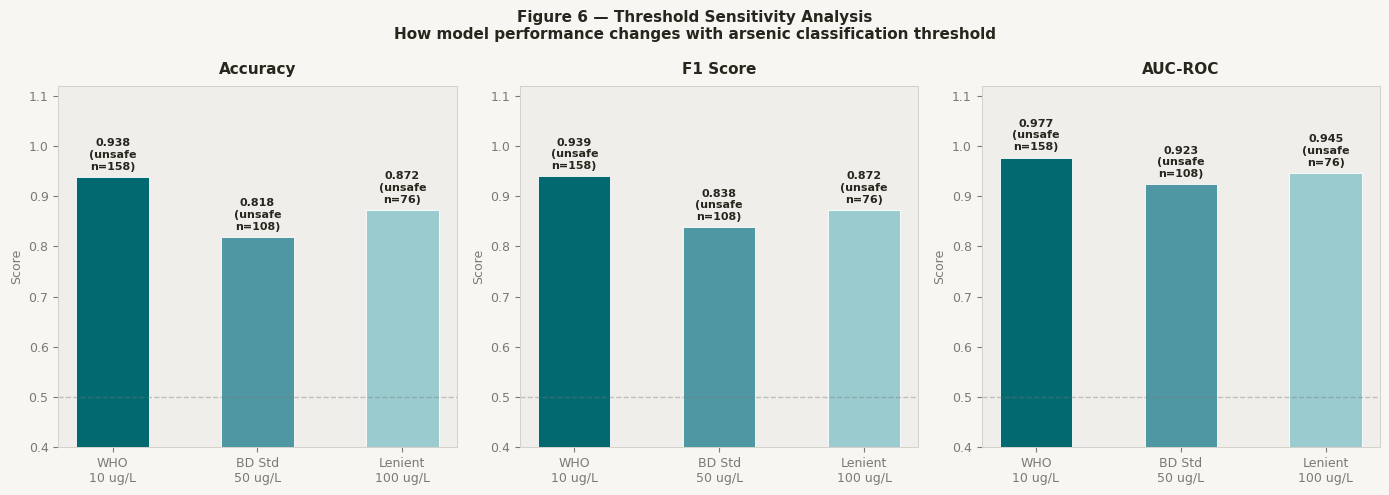

Saved: figure6_threshold_sensitivity.png


In [ ]:

# ════════════════════════════════════════════════════════════
# CELL 11 ▸ Figure 6 — Threshold Sensitivity
# WHO 10 vs Bangladesh 50 vs Lenient 100 ug/L
# ════════════════════════════════════════════════════════════

thresholds    = [(10, 'WHO\n10 ug/L'), (50, 'BD Std\n50 ug/L'), (100, 'Lenient\n100 ug/L')]
thresh_results = {}

print("\nThreshold Sensitivity (RF, SMOTE, IoT features):")
print(f"{'Threshold':<15} {'n_unsafe':>8} {'Acc':>8} {'F1':>8} {'AUC':>8}")
print("-"*50)

for thresh, t_lbl in thresholds:
    yt   = (df[TARGET_COL] >= thresh).astype(int)
    Xs2, ys2 = smote_resample(X_imp, yt)
    Xtr, Xte, ytr, yte = train_test_split(Xs2, ys2, test_size=0.2, random_state=42, stratify=ys2)
    m = RandomForestClassifier(n_estimators=300, random_state=42)
    m.fit(Xtr, ytr)
    yp = m.predict(Xte); ypr = m.predict_proba(Xte)[:, 1]
    thresh_results[t_lbl] = {
        'n_unsafe': int(sum(yt == 1)),
        'acc' : accuracy_score(yte, yp),
        'f1'  : f1_score(yte, yp),
        'auc' : roc_auc_score(yte, ypr),
    }
    r = thresh_results[t_lbl]
    print(f"{t_lbl.replace(chr(10),' '):<15} {r['n_unsafe']:>8} {r['acc']:>8.4f} {r['f1']:>8.4f} {r['auc']:>8.4f}")

# Plot
fig, axes = plt.subplots(1, 3, figsize=(14, 5), facecolor=C_BG)
fig.suptitle('Figure 6 — Threshold Sensitivity Analysis\n'
             'How model performance changes with arsenic classification threshold',
             fontsize=11, fontweight='bold', color=C_TEXT)

t_labels   = list(thresh_results.keys())
t_cols     = [C_TEAL, '#4f98a3', '#9acbcf']
t_metrics  = [('Accuracy','acc'), ('F1 Score','f1'), ('AUC-ROC','auc')]

for ax, (m_lbl, m_key) in zip(axes, t_metrics):
    vals = [thresh_results[t][m_key] for t in t_labels]
    bars = ax.bar(t_labels, vals, color=t_cols, edgecolor='white', lw=0.6, width=0.5)
    ax.set_facecolor(C_SURF)
    for sp in ax.spines.values(): sp.set_edgecolor(C_BORDER); sp.set_linewidth(0.7)
    ax.set_ylim(0.4, 1.12)
    ax.axhline(0.5, color=C_MUTED, ls='--', lw=1, alpha=0.4)
    ax.set_title(m_lbl, fontsize=11, fontweight='bold', color=C_TEXT, pad=8)
    ax.tick_params(colors=C_MUTED, labelsize=9)
    ax.set_ylabel('Score', fontsize=9, color=C_MUTED)
    n_vals = [thresh_results[t]['n_unsafe'] for t in t_labels]
    for bar, val, nv in zip(bars, vals, n_vals):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.015,
                f'{val:.3f}\n(unsafe\nn={nv})', ha='center', fontsize=8,
                color=C_TEXT, fontweight='600')

plt.tight_layout()
plt.savefig('figure6_threshold_sensitivity.png', dpi=150, bbox_inches='tight', facecolor=C_BG)
plt.show()
print("Saved: figure6_threshold_sensitivity.png")



National Survey: 3534 wells | Safe=2650 (75.0%) | Unsafe=884 (25.0%)

Cross-Dataset: Acc=0.6899  BalAcc=0.6609  F1=0.4931  AUC=0.7556
              precision    recall  f1-score   support

        Safe       0.84      0.72      0.78      2650
      Unsafe       0.42      0.60      0.49       884

    accuracy                           0.69      3534
   macro avg       0.63      0.66      0.63      3534
weighted avg       0.74      0.69      0.71      3534



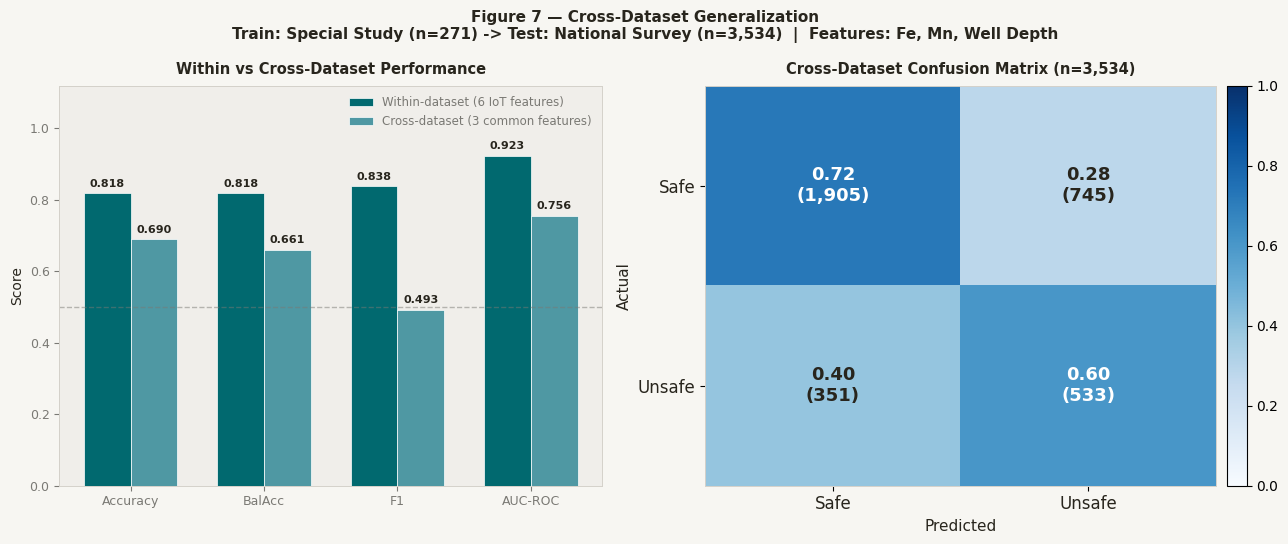

Saved: figure7_cross_dataset.png


In [ ]:

# ════════════════════════════════════════════════════════════
# CELL 12 ▸ Figure 7 — Cross-Dataset Validation
# Train on Special Study -> Test on National Survey (3,534 wells)
# Upload NationalSurveyData.csv before running this cell
# ════════════════════════════════════════════════════════════

COMMON_FEATURES = ['Fe', 'Mn', 'WELL_DEPTH']

with open('NationalSurveyData.csv', 'r', encoding='utf-8') as f:
    nlines = f.read().split('\n')
df_nat = pd.read_csv(io.StringIO('\n'.join(nlines[4:])), low_memory=False)
df_nat = df_nat.drop(index=0).reset_index(drop=True)

for col in COMMON_FEATURES + ['As']:
    if col in df_nat.columns:
        df_nat[col] = df_nat[col].apply(clean_numeric)

df_nat_c = df_nat.dropna(subset=['As']).copy()
df_nat_c['label'] = (df_nat_c['As'] >= BD_THRESHOLD).astype(int)

X_nat = pd.DataFrame(
    SimpleImputer(strategy='median').fit_transform(df_nat_c[COMMON_FEATURES]),
    columns=COMMON_FEATURES
)
y_nat = df_nat_c['label'].values

print(f"National Survey: {len(df_nat_c)} wells | "
      f"Safe={sum(y_nat==0)} ({sum(y_nat==0)/len(y_nat)*100:.1f}%) | "
      f"Unsafe={sum(y_nat==1)} ({sum(y_nat==1)/len(y_nat)*100:.1f}%)")

# Retrain on Special Study using only common features
X_sp  = pd.DataFrame(
    SimpleImputer(strategy='median').fit_transform(df[COMMON_FEATURES]),
    columns=COMMON_FEATURES
)
X_sp2, y_sp2 = smote_resample(X_sp, y_raw)
cross_model = RandomForestClassifier(n_estimators=300, random_state=42)
cross_model.fit(X_sp2, y_sp2)

y_nat_pred = cross_model.predict(X_nat)
y_nat_prob = cross_model.predict_proba(X_nat)[:, 1]

cd_acc = accuracy_score(y_nat, y_nat_pred)
cd_ba  = balanced_accuracy_score(y_nat, y_nat_pred)
cd_f1  = f1_score(y_nat, y_nat_pred)
cd_auc = roc_auc_score(y_nat, y_nat_prob)
cd_cm  = confusion_matrix(y_nat, y_nat_pred)

print(f"\nCross-Dataset: Acc={cd_acc:.4f}  BalAcc={cd_ba:.4f}  F1={cd_f1:.4f}  AUC={cd_auc:.4f}")
print(classification_report(y_nat, y_nat_pred, target_names=['Safe', 'Unsafe']))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), facecolor=C_BG)
fig.suptitle('Figure 7 — Cross-Dataset Generalization\n'
             'Train: Special Study (n=271) -> Test: National Survey (n=3,534)  |  Features: Fe, Mn, Well Depth',
             fontsize=11, fontweight='bold', color=C_TEXT)

metrics_compare = ['Accuracy', 'BalAcc', 'F1', 'AUC-ROC']
within_vals = [results[best_name]['test_acc'], results[best_name]['test_ba'],
               results[best_name]['test_f1'],  results[best_name]['test_auc']]
cross_vals  = [cd_acc, cd_ba, cd_f1, cd_auc]
x = np.arange(4); w = 0.35

b1 = ax1.bar(x - w/2, within_vals, w, color=C_TEAL,   edgecolor='white', lw=0.5,
             label='Within-dataset (6 IoT features)')
b2 = ax1.bar(x + w/2, cross_vals,  w, color='#4f98a3', edgecolor='white', lw=0.5,
             label='Cross-dataset (3 common features)')
ax1.set_xticks(x); ax1.set_xticklabels(metrics_compare, fontsize=9)
ax1.set_ylim(0, 1.12)
ax1.axhline(0.5, color=C_MUTED, ls='--', lw=1, alpha=0.5)
ax1.set_facecolor(C_SURF)
for sp in ax1.spines.values(): sp.set_edgecolor(C_BORDER); sp.set_linewidth(0.7)
ax1.set_ylabel('Score', fontsize=10, color=C_TEXT)
ax1.set_title('Within vs Cross-Dataset Performance', fontsize=10.5, fontweight='bold', color=C_TEXT, pad=8)
ax1.legend(fontsize=8.5, frameon=False, labelcolor=C_MUTED)
ax1.tick_params(colors=C_MUTED, labelsize=9)
for bar, val in zip(list(b1) + list(b2), within_vals + cross_vals):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.018,
             f'{val:.3f}', ha='center', fontsize=8, color=C_TEXT, fontweight='600')

cm_norm = cd_cm / cd_cm.sum(axis=1, keepdims=True)
im2 = ax2.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1, aspect='auto')
ax2.set_xticks([0,1]); ax2.set_yticks([0,1])
ax2.set_xticklabels(['Safe', 'Unsafe'], fontsize=12, color=C_TEXT)
ax2.set_yticklabels(['Safe', 'Unsafe'], fontsize=12, color=C_TEXT)
ax2.set_xlabel('Predicted', fontsize=11, color=C_TEXT)
ax2.set_ylabel('Actual', fontsize=11, color=C_TEXT)
ax2.set_facecolor(C_SURF)
for sp in ax2.spines.values(): sp.set_edgecolor(C_BORDER); sp.set_linewidth(0.7)
ax2.set_title(f'Cross-Dataset Confusion Matrix (n={len(y_nat):,})', fontsize=10.5,
              fontweight='bold', color=C_TEXT, pad=8)
for i in range(2):
    for j in range(2):
        ax2.text(j, i, f'{cm_norm[i,j]:.2f}\n({cd_cm[i,j]:,})',
                 ha='center', va='center', fontsize=13, fontweight='bold',
                 color='white' if cm_norm[i,j] > 0.55 else C_TEXT)
plt.colorbar(im2, ax=ax2, fraction=0.04, pad=0.02)
plt.tight_layout()
plt.savefig('figure7_cross_dataset.png', dpi=150, bbox_inches='tight', facecolor=C_BG)
plt.show()
print("Saved: figure7_cross_dataset.png")


In [ ]:

# ════════════════════════════════════════════════════════════
# CELL 13 ▸ Final Summary
# ════════════════════════════════════════════════════════════

print("\n" + "="*70)
print("FINAL RESULTS SUMMARY — GROUNDWATER ARSENIC SAFETY PREDICTION")
print("Threshold: Bangladesh Standard = 50 ug/L  |  Method: SMOTE + RF/XGB/GBM")
print("="*70)

rows = []
for name, r in results.items():
    rows.append({
        'Model'           : name,
        'CV Acc (mean)'   : f"{r['cv_mean']:.4f}",
        'CV Acc (+/-std)' : f"{r['cv_std']:.4f}",
        'Test Accuracy'   : f"{r['test_acc']:.4f}",
        'Balanced Acc'    : f"{r['test_ba']:.4f}",
        'F1 Score'        : f"{r['test_f1']:.4f}",
        'AUC-ROC'         : f"{r['test_auc']:.4f}",
    })
print(pd.DataFrame(rows).to_string(index=False))

print(f"\n--- Scenario Comparison (RF) ---")
for s, r in scen_results.items():
    print(f"  {s:<22} n_feat={r['n']:2d}  Acc={r['acc']:.4f}  F1={r['f1']:.4f}  AUC={r['auc']:.4f}")

print(f"\n--- Threshold Sensitivity (RF) ---")
for t, r in thresh_results.items():
    tl = t.replace('\n',' ')
    print(f"  {tl:<20} n_unsafe={r['n_unsafe']:3d}  Acc={r['acc']:.4f}  F1={r['f1']:.4f}  AUC={r['auc']:.4f}")

print(f"\n--- Cross-Dataset (n=3,534) ---")
print(f"  Acc={cd_acc:.4f}  BalAcc={cd_ba:.4f}  F1={cd_f1:.4f}  AUC={cd_auc:.4f}")

print(f"\nBest Model     : {best_name}")
print(f"IoT Features   : {IOT_FEATURES}")
print(f"Hardware Cost  : ~$20 USD (ESP32 + sensors) + ~$0.50/test (Fe+Mn strips)")
print("="*70)
print("\nAll figures saved:")
for fig_f in ['figure1_model_comparison.png', 'figure2_cm_roc.png',
              'figure3_per_class.png',         'figure4_shap.png',
              'figure5_scenario_comparison.png','figure6_threshold_sensitivity.png',
              'figure7_cross_dataset.png']:
    print(f"  {fig_f}")



FINAL RESULTS SUMMARY — GROUNDWATER ARSENIC SAFETY PREDICTION
Threshold: Bangladesh Standard = 50 ug/L  |  Method: SMOTE + RF/XGB/GBM
              Model CV Acc (mean) CV Acc (+/-std) Test Accuracy Balanced Acc F1 Score AUC-ROC
Logistic Regression        0.7692          0.0644        0.7879       0.7879   0.8000  0.8742
 Random Forest (RF)        0.8346          0.0196        0.8182       0.8182   0.8378  0.9233
          MLP (ANN)        0.5692          0.0591        0.7424       0.7424   0.7606  0.8301
            XGBoost        0.8154          0.0432        0.7879       0.7879   0.8056  0.8999
  Gradient Boosting        0.8462          0.0403        0.8333       0.8333   0.8493  0.9109

--- Scenario Comparison (RF) ---
  Full Lab               n_feat=63  Acc=0.9242  F1=0.9296  AUC=0.9835
  IoT + Fe/Mn Kit        n_feat= 6  Acc=0.8182  F1=0.8378  AUC=0.9233
  Sensor Only            n_feat= 4  Acc=0.7879  F1=0.8108  AUC=0.8471

--- Threshold Sensitivity (RF) ---
  WHO 10 ug/L        